# 27 - Dataset da Camada 1 (histórico, 30 m) para o Modelo A

| | |
|---|---|
| **Tarefa do plano** | S2-10 - `train_historico.parquet` |
| **O que faz** | Monta a tabela de treino do modelo de suscetibilidade a cheias |
| **Usa** | Stack estático (21), séries mensais (22–24), Landsat e JRC mensais, `labels.gpkg` (26) |
| **Produz** | `data/processed/training/train_historico.parquet` + dicionário + metadados |

**Ideia simples.** Cada linha da tabela é **um píxel de 30 m num mês**, com:

- a resposta (rótulo): era água? era cheia?
- o terreno desse píxel (altitude, declive, HAND, distância ao rio...);
- as condições desse mês (chuva, humidade do solo, caudal) e do mês anterior;
- o que o Landsat viu (bandas e índices), quando viu.

**Porque é uma amostra.** O domínio tem 1,3 milhões de píxeis; vezes 192 meses
seriam 259 milhões de linhas. Em cada mês sorteiam-se até 4 000 píxeis, por
grupos (estratos), para garantir exemplos de todos os casos:

| Estrato | O que é | Por mês |
|---|---|---|
| `flood` | água fora da água permanente | até 1 500 |
| `permanent` | água permanente (rio, lagoas) | até 300 |
| `dry_low` | seco em terreno baixo (o caso difícil) | até 1 500 |
| `dry_other` | seco no resto | até 700 |

A coluna `weight` diz quantos píxeis reais cada linha representa. Píxeis que o
JRC não observou nesse mês (nuvens) nunca entram: não se inventa a resposta.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Construir a tabela

In [2]:
table = training.build_historical(cfg)
out = config.path(cfg, "training", "train_historico.parquet")
print("escrito:", out.relative_to(ROOT))
table.head(3).T

camada 1:   0%|          | 0/193 [00:00<?, ?it/s]

escrito: data/processed/training/train_historico.parquet


,0,1,2
month,2006-01,2006-01,2006-01
year,2006,2006,2006
month_num,1,1,1
season,wet,wet,wet
row,105,941,42
...,...,...,...
sm_root_cal_district,0.171,0.171,0.171
rain_basin_mm_lag1,NaN,NaN,NaN
rain_district_mm_lag1,NaN,NaN,NaN
sm_cal_basin_lag1,NaN,NaN,NaN


## 2. Controlo de qualidade da tabela

In [3]:
print(f"{len(table):,} linhas x {table.shape[1]} colunas | {table['month'].nunique()} meses | ficheiro {out.stat().st_size / 1e6:.0f} MB")
display(table.groupby(["split", "stratum"], observed=True).size().unstack(fill_value=0))
resumo = table.groupby("split", observed=True).apply(lambda g: pd.Series({
    "linhas": len(g), "água_pct": 100 * g["label_water"].mean(), "cheia_pct": 100 * g["label_flood"].mean(),
    "cheia_pct_real": 100 * np.average(g["label_flood"], weights=g["weight"])}), include_groups=False)
resumo

670,243 linhas x 80 colunas | 171 meses | ficheiro 42 MB


stratum,dry_low,dry_other,ems,flood,permanent
split,,,,,
test,0,0,40000,0,0
train,223500,104300,0,182944,39600
val,31500,14700,0,27999,5700


,linhas,água_pct,cheia_pct,cheia_pct_real
split,,,,
test,"40,000.000",50.000,49.995,59.639
train,"550,344.000",40.437,33.242,0.348
val,"79,899.000",42.177,35.043,0.764


`cheia_pct` é a proporção na amostra (as cheias foram sorteadas de propósito em
maior número). `cheia_pct_real` usa os pesos e dá a proporção verdadeira no
terreno: mostra quão raro é o que o modelo tem de aprender.

## 3. Dicionário de dados e valores em falta

In [4]:
dicionario = training.data_dictionary(table)
dicionario.to_csv(out.with_name(out.stem + "_dicionario.csv"), index=False)
display(dicionario.groupby("grupo").agg(colunas=("coluna", "count"), em_falta_pct_medio=("em_falta_pct", "mean")).round(1))
dicionario[dicionario["em_falta_pct"] > 0].sort_values("em_falta_pct", ascending=False).head(15)

,colunas,em_falta_pct_medio
grupo,,
amostragem,2,0.000
caudal,5,0.100
chuva,14,0.100
hidrometeorologia,6,0.000
humidade_solo,13,16.000
landsat,14,20.900
metadados,9,0.000
rotulo,3,0.000
rotulo_auxiliar,1,0.000


,coluna,grupo,descricao,unidade,tipo,em_falta_pct
64,smap_surface_basin,humidade_solo,"Humidade do solo (ERA5-Land, ERA5-Land calibra...",m3/m3,float32,52.000
65,smap_surface_district,humidade_solo,"Humidade do solo (ERA5-Land, ERA5-Land calibra...",m3/m3,float32,52.000
66,smap_rootzone_basin,humidade_solo,"Humidade do solo (ERA5-Land, ERA5-Land calibra...",m3/m3,float32,52.000
67,smap_rootzone_district,humidade_solo,"Humidade do solo (ERA5-Land, ERA5-Land calibra...",m3/m3,float32,52.000
37,ndmi,landsat,Índice espectral Landsat,,float32,24.700
35,mndwi,landsat,Índice espectral Landsat,,float32,24.400
36,ndvi,landsat,Índice espectral Landsat,,float32,24.400
34,ndwi,landsat,Índice espectral Landsat,,float32,24.400
31,nir,landsat,Refletância de superfície Landsat (mediana men...,0-1,float32,24.300
30,red,landsat,Refletância de superfície Landsat (mediana men...,0-1,float32,24.300


## 4. Os dados fazem sentido?

,hand,distance_to_river_m,twi,mndwi,rain_basin_mm,q_mean,sm_cal_basin
label_flood,,,,,,,
0,2.100,"5,568.210",10.500,-0.500,60.480,15.860,0.120
1,0.000,30.000,11.900,0.230,65.460,16.380,0.120


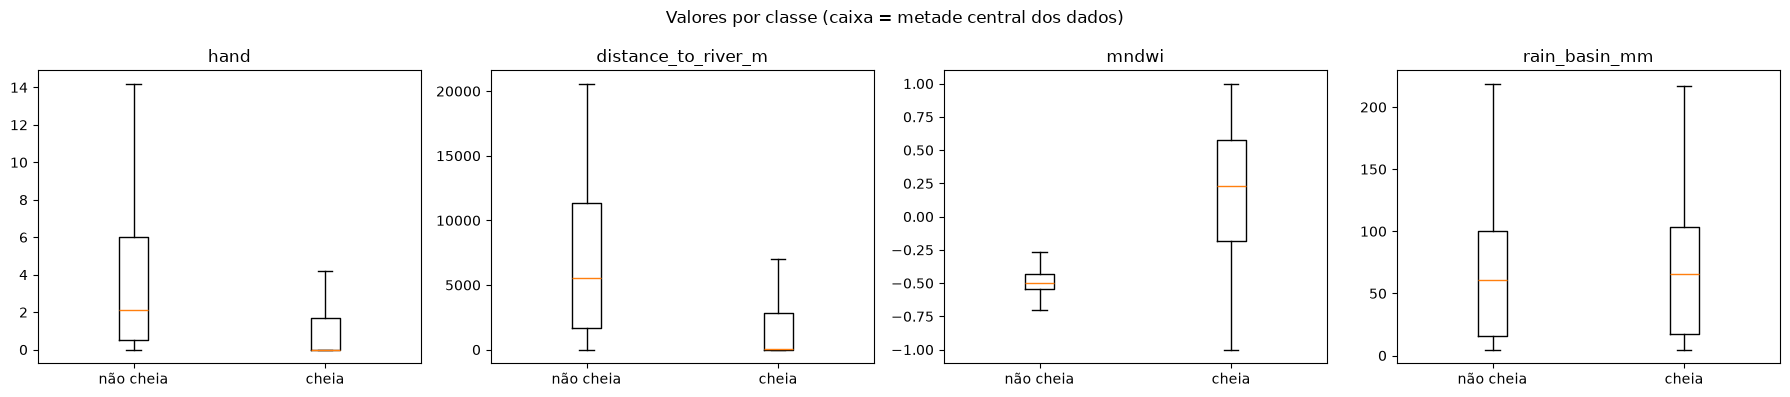

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["hand", "distance_to_river_m", "mndwi", "rain_basin_mm"]):
    data = [table.loc[table["label_flood"] == v, col].dropna() for v in (0, 1)]
    ax.boxplot(data, tick_labels=["não cheia", "cheia"], showfliers=False); ax.set_title(col)
plt.suptitle("Valores por classe (caixa = metade central dos dados)"); plt.tight_layout()
plt.savefig(REPORTS / "27_features_por_classe.png", dpi=110)
table.groupby("label_flood")[["hand", "distance_to_river_m", "twi", "mndwi", "rain_basin_mm", "q_mean", "sm_cal_basin"]].median().round(2)

**O que se espera ver:** a água não permanente em terreno mais baixo (HAND menor),
mais perto do rio, com MNDWI mais alto.

**Atenção ao significado de `label_flood`.** É "água fora da água permanente".
Inclui as cheias, mas também a água sazonal normal (zonas húmidas e margens que
enchem todos os anos). Por isso há linhas `flood` em todos os meses, mesmo nos
secos. A chuva mediana das duas classes é igual por essa razão e porque a
amostra tira o mesmo número de linhas em cada mês. O que varia com a chuva é a
**área** de água, que se vê com os pesos:

,agua_nao_permanente_pct,chuva_bacia_mm,caudal_medio
agua_nao_permanente_pct,1.000,-0.030,-0.030
chuva_bacia_mm,-0.030,1.000,0.740
caudal_medio,-0.030,0.740,1.000


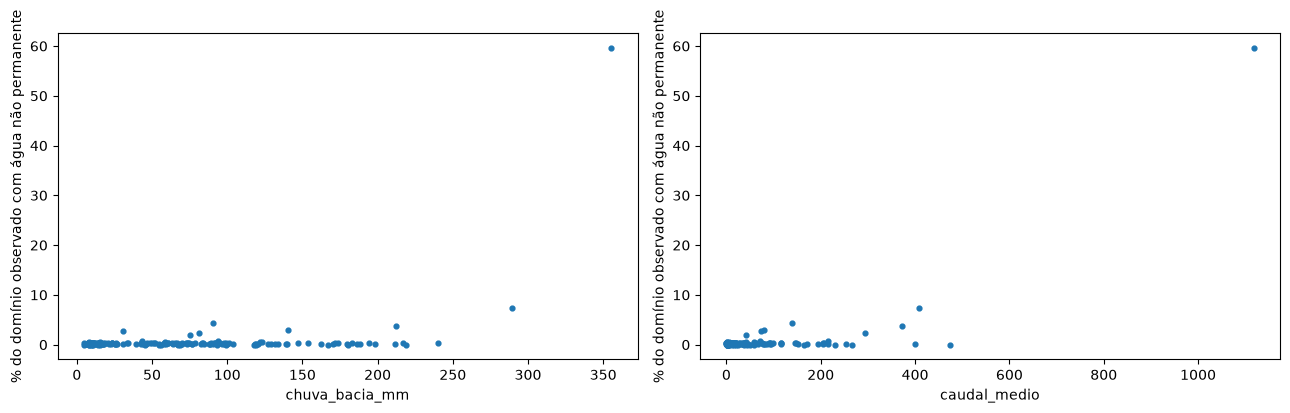

In [6]:
area = table.groupby("month", observed=True).apply(lambda g: pd.Series({
    "agua_nao_permanente_pct": 100 * np.average(g["label_flood"], weights=g["weight"]),
    "chuva_bacia_mm": g["rain_basin_mm"].iloc[0], "caudal_medio": g["q_mean"].iloc[0]}), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["chuva_bacia_mm", "caudal_medio"]):
    ax.scatter(area[col], area["agua_nao_permanente_pct"], s=12); ax.set_xlabel(col); ax.set_ylabel("% do domínio observado com água não permanente")
plt.tight_layout(); plt.savefig(REPORTS / "27_area_de_agua_vs_chuva.png", dpi=110)
area.corr(method="spearman").round(2)

**Resultado medido: a correlação é praticamente zero** (cerca de −0,05). A área
de água do JRC não sobe e desce com a chuva nem com o caudal mês a mês. A água
de cheia aparece só em poucos meses, e quase sempre no mês da chuva forte ou no
seguinte (quando as nuvens já abriram):

In [7]:
jrc = drivers.read_table(cfg, "jrc_monthly_summary")
drv = drivers.load_monthly_drivers(cfg)
top = jrc[jrc["jrc_observed_fraction"] >= 0.9].nlargest(8, "jrc_flood_km2").join(
    drv[["rain_basin_mm", "rain_basin_mm_lag1", "q_max"]]).rename(columns={"rain_basin_mm_lag1": "chuva_mes_anterior_mm"})
top.round(1)

,jrc_observed_fraction,jrc_flood_km2,rain_basin_mm,chuva_mes_anterior_mm,q_max
month,,,,,
2021-03,1.000,54.000,90.700,289.200,319.300
2014-03,1.000,46.600,212.000,76.700,727.800
2014-04,1.000,32.800,30.900,212.000,158.000
2006-04,1.000,10.000,43.300,198.200,609.800
2021-09,1.000,5.800,15.700,9.300,1.500
2021-10,1.000,5.700,58.500,15.700,17.600
2014-07,1.000,5.400,8.200,8.600,0.900
2019-01,1.000,5.200,122.900,131.600,211.000


**O que isto significa para o Modelo A**

- Em 16 anos de rótulos há apenas cerca de meia dúzia de meses com cheia
  claramente visível (2021, 2014, 2012, 2006). Eventos grandes como janeiro de
  2013 não aparecem, porque o JRC só observou 10 % da área nesse mês.
- Com tão poucos exemplos de cheia, o modelo vai aprender sobretudo **onde** a
  água costuma estar (terreno), e pouco sobre **quando** (chuva e caudal). O
  resultado realista é um mapa de suscetibilidade baseado no terreno, com uma
  componente dinâmica fraca.
- A parte "quando" do sistema de alertas deve apoiar-se nos gatilhos de chuva e
  caudal (notebooks 22 e 23) e no Modelo B, e não no Modelo A.

## Aviso importante para o Modelo A (Semana 3)

Esta tabela tem todas as colunas previstas no plano, mas **nem todas devem ser
usadas como features do Modelo A**:

- `jrc_occurrence`: é a frequência histórica do próprio rótulo. Usá-la seria
  dar a resposta ao modelo.
- Bandas e índices Landsat do **mesmo mês**: o rótulo JRC é calculado a partir
  dessas mesmas imagens Landsat. Com elas, o modelo aprende "MNDWI alto = água",
  o que é deteção e não suscetibilidade, e os resultados parecem ótimos sem o
  serem.

Para responder à pergunta do Modelo A ("que zonas inundam, e em que condições de
chuva e caudal?"), as features honestas são o **terreno** e as **condições
hidrometeorológicas**. As colunas Landsat ficam na tabela para análise e para
comparação, e a decisão final é tomada na Semana 3.

Outra limitação: a tabela só tem linhas com rótulo, ou seja, até 2021. O teste em
2022–2026 só existirá quando houver polígonos em `labels.gpkg`.